In [1]:
import numpy as np
from rich import print
from contingency import Contingent
import contingency.plots as cntyplt
import matplotlib.pyplot as plt

# from contingency.plots import PR_contour,ROC_contour


rng=np.random.default_rng(2)
np.set_printoptions(formatter={'float_kind':"{:.5g}".format})

# y_true = np.array([0,1,0,0,1,1,0,0]).astype(bool)
y_true = (rng.random(100)>0.6).astype(bool)
# y_prob = np.array([0.1,0.8,0.1,.7,.25,0.68,0.5,0.6])
y_pred = np.where(rng.random(100)<0.05, 1-y_true, y_true).astype(bool)

# y_pred = np.array([0,1,0,1,0,1,0,1]).astype(bool)
y_prob = rng.beta(
    np.where(y_true, 3, 2.),
    np.where(y_true, 2., 4)
)

# M = Contingent(y_pred = y_pred, y_true=y_true)
M = Contingent.from_scalar(y_true, y_prob)

f1_thres,f1_opt = M.optimize('F', include_thres=True)
mcc_thres,mcc_opt = M.optimize('mcc', include_thres=True)

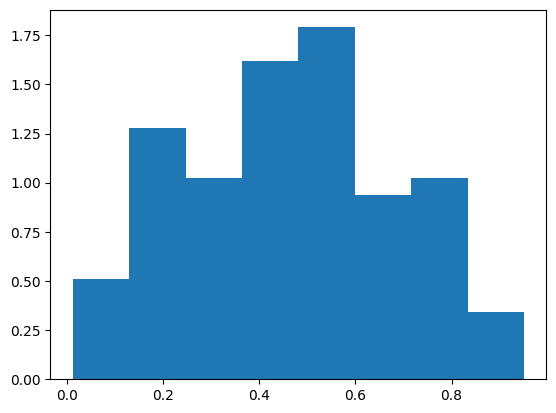

In [2]:
plt.hist(y_prob, bins='auto', density=True);

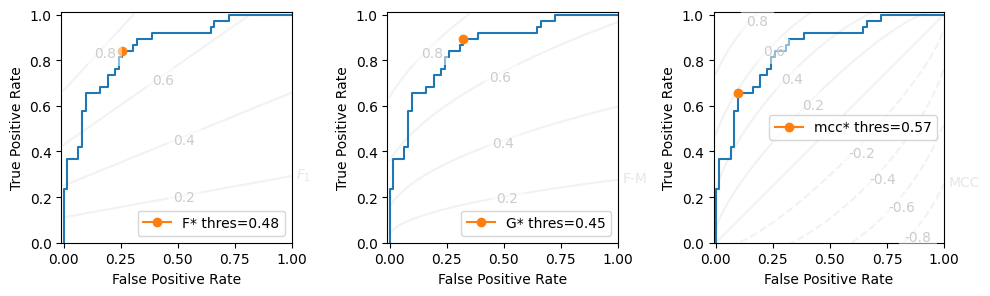

In [3]:
f,axes = plt.subplots(ncols=3, figsize=(10,5))

for metric, ax in zip(['F', 'G', 'mcc'], axes.flatten()):
    met_thres,met_opt = M.optimize(metric, include_thres=True)
    
    cntyplt.ROC_contour(M.imbalance, metric, ax=ax)
    ax.plot(1-M.TNR, M.TPR)
    ax.plot(met_opt.FPR, met_opt.TPR, marker='o', label=metric+f'* thres={met_thres:.2f}')
    # ax.plot(mcc_opt.FPR, mcc_opt.TPR, marker='o', label=f'MCC thres={mcc_thres:.2f}', c='g')
    
    ax.legend()
plt.tight_layout()

# plt.gca().spines[['top', 'right']].set_visible(False)

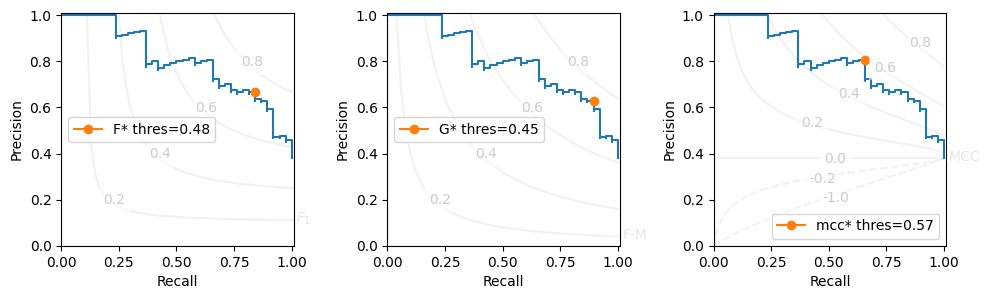

In [4]:
f,axes = plt.subplots(ncols=3, figsize=(10,5))

for metric, ax in zip(['F', 'G', 'mcc'], axes.flatten()):
    met_thres,met_opt = M.optimize(metric, include_thres=True)
    
    cntyplt.PR_contour(M.imbalance, metric, ax=ax)
    ax.step(M.recall, M.precision, where='post')
    ax.plot(met_opt.recall, met_opt.precision, marker='o', label=metric+f'* thres={met_thres:.2f}')
    # ax.plot(mcc_opt.FPR, mcc_opt.TPR, marker='o', label=f'MCC thres={mcc_thres:.2f}', c='g')
    
    ax.legend()
plt.tight_layout()

np.float64(1.631578947368421)

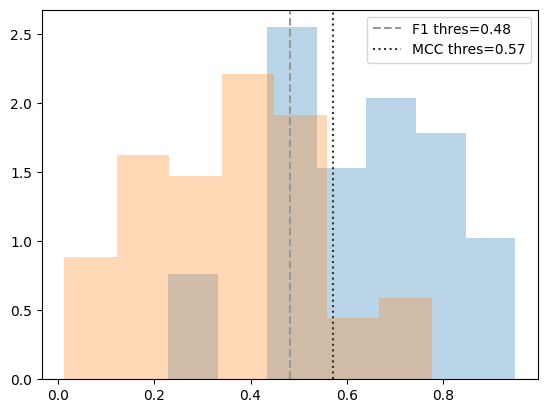

In [11]:
# def true_pred_dists(y_true, y_pred, **hist_kws): 

plt.hist(y_prob[y_true], bins='auto', density=True, alpha=0.3, color='C0')
plt.hist(y_prob[~y_true], bins='auto', density=True, alpha=0.3, color='C1')
# plt.axvline(0.5, color='0.4', ls='--')
plt.axvline(f1_thres, ls='--', c='0.6', label=f'F1 thres={f1_thres:.2f}')
plt.axvline(mcc_thres, ls=':', c='0.2', label=f'MCC thres={mcc_thres:.2f}')
plt.legend()
M.imbalance

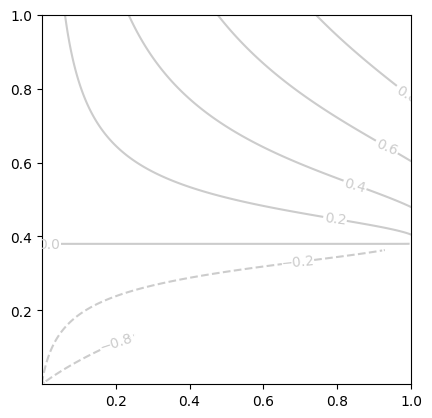

In [41]:
## Could migrate to a contour-based system....\shrug
r = M.imbalance
# x = np.linspace(1e-4, 1, 300)
grid = np.linspace(1e-4, 1, 500)
R,P = np.meshgrid(grid,grid)
valid = P >= R / (R + r)
MCC = np.where(
    valid,
    np.sqrt(R) * (P * (r + 1) - 1) / np.sqrt(np.maximum(r * (P * (r + 1) - R), 1e-12)),
    np.nan,
)
# MCC = np.sqrt(X)*(Y*(1.63+1)-1)/np.sqrt(1.63*(Y*(1.63+1)-X))
C = plt.contour(R,P,MCC, levels=[-.8,-0.2, 0., 0.2, 0.4, 0.6, 0.8], colors='0.8')
plt.clabel(C)
plt.gca().set_aspect(1)

In [ ]:
import sympy as sp

R, P, FPR, t, r, beta = sp.symbols('R P FPR t r beta', positive=True)

# 1. Normalized confusion matrix (P_pos = 1, N_neg = r)
TP = R
FN = 1 - R
FP = r * FPR
TN = r * (1 - FPR)

prec_expr = TP / (TP + FP)  # R / (R + r * FPR)
fpr_from_p = sp.solve(sp.Eq(P, prec_expr), FPR)  # R * (1 - P) / (r * P)

# 2. Define metrics in terms of (R, FPR, r, beta)
metrics = {
    "MCC": (TP * TN - FP * FN) / sp.sqrt((TP + FP) * (TP + FN) * (TN + FP) * (TN + FN)),
    "F1": (2 * TP) / (2 * TP + FP + FN),
    "F_beta": ((1 + beta**2) * TP) / ((1 + beta**2) * TP + FP + beta**2 * FN),
    "FM": sp.sqrt(prec_expr * R),
}

for name, expr in metrics.items():
    print(f"================ {name} ================")

    # --- A. ROC SPACE: Solve expr^2 = t^2 for TPR (= R) in terms of FPR ---
    roc_eq = sp.expand(sp.numer(sp.together(expr**2 - t**2)))
    tpr_roots = [sp.simplify(root) for root in sp.solve(roc_eq, R)]
    print("ROC TPR(FPR; t, r) roots:")
    for root in tpr_roots:
        print(" ", root)

    # ROC FPR bounds (where TPR = 1 for upper branch, TPR = 0 for lower branch)
    fpr_at_tpr1 = [sp.simplify(sol) for sol in sp.solve(roc_eq.subs(R, 1), FPR)]
    fpr_at_tpr0 = [sp.simplify(sol) for sol in sp.solve(roc_eq.subs(R, 0), FPR) if sol != 0]
    print(f"ROC FPR where TPR = 1: {fpr_at_tpr1}")
    print(f"ROC FPR where TPR = 0: {fpr_at_tpr0}")

    # --- B. PR SPACE: Substitute FPR(P, R) and solve for P(R; t, r) ---
    pr_metric_sq = sp.simplify(expr.subs(FPR, fpr_from_p)**2)
    pr_eq = sp.expand(sp.numer(sp.together(pr_metric_sq - t**2)))
    p_roots = [sp.simplify(root) for root in sp.solve(pr_eq, P)]
    print("PR P(R; t, r) roots:")
    for root in p_roots:
        print(" ", root)

    # PR Recall bounds:
    # Upper edge P = 1 (FPR = 0) gives R_min
    r_at_p1 = [sp.simplify(sol) for sol in sp.solve(pr_eq.subs(P, 1), R)]
    # Lower edge P = R / (R + r) (FPR = 1) gives R_max
    p_floor = R / (R + r)
    r_at_pfloor = [sp.simplify(sol) for sol in sp.solve(pr_eq.subs(P, p_floor), R) if sol != 0]
    print(f"PR R_min (at P = 1):       {r_at_p1}")
    print(f"PR R_max (at P = P_floor): {r_at_pfloor}\n")
